# Random Forest — Ansiedade (Multinível)

Objetivo: classificar a severidade da ansiedade em quatro níveis (1, 2, 3 e 4), com base em variáveis gerais, socioeconômicas e de saúde.

## 1. Bibliotecas e configurações

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, ParameterSampler
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, accuracy_score, roc_auc_score, balanced_accuracy_score
)

RANDOM_STATE = 42
ID_COL = "ID_DOMICILIO"
WEIGHT_COL = "PESO_AMOSTRAL"
TARGET = "SEVERIDADE_ANSIEDADE"

DATA_PATH = Path("adult25_limpo.csv")
df_original = pd.read_csv(DATA_PATH)

print("Dimensões da base:", df_original.shape)
print("Colunas:", len(df_original.columns))


Dimensões da base: (24215, 73)
Colunas: 73


## 2. Carregamento e auditoria da base

In [ ]:
# Categorias válidas da variável-alvo GADCAT_A:
# 1 = mínima/nenhuma; 2 = leve; 3 = moderada; 4 = severa.
# -1 representa resposta desconhecida/indeterminada.
df = df_original.copy()
df = df.set_index(ID_COL)

df = df[df[TARGET].isin([1, 2, 3, 4])].copy()

COLUNAS_ANSIEDADE = [
    "HISTORICO_TRANSTORNO_ANSIEDADE",
    "MED_ANSIEDADE",
    "FREQ_ANSIEDADE",
    "INTENSIDADE_ANSIEDADE",
    "FREQ_ANSIEDADE_2SEM",
    "FREQ_PREOCUPACAO_INCONTROLAVEL_2SEM",
    "FREQ_PREOCUPACAO_DESNECESSARIA_2SEM",
    "FREQ_DIFICULDADE_DESCANSAR_2SEM",
    "FREQ_AGITACAO_INQUIETA",
    "FREQ_IRRITABILIDADE_2SEM",
    "FREQ_MEDO_2SEM",
]


COLUNAS_DEPRESSAO = [
    c for c in df.columns
    if ("DEPRESS" in c.upper()) or ("PHQ" in c.upper()) or ("MDD" in c.upper())
]

colunas_remover = [ID_COL, WEIGHT_COL, TARGET] + COLUNAS_ANSIEDADE + COLUNAS_DEPRESSAO
X_base = df.drop(columns=[c for c in colunas_remover if c in df.columns])
y_base = df[TARGET].astype(int)
pesos_base = df[WEIGHT_COL].astype(float)

# Auditoria: conferir se nenhuma coluna proibida permaneceu em X.
assert TARGET not in X_base.columns
assert not any(("DEPRESS" in c.upper()) or ("PHQ" in c.upper()) or ("MDD" in c.upper())
               for c in X_base.columns)
assert not any(c in X_base.columns for c in COLUNAS_ANSIEDADE)

print("Registros com target válido:", len(df))
print("Variáveis preditoras candidatas:", len(X_base.columns))
print("Variáveis de ansiedade removidas:", [c for c in COLUNAS_ANSIEDADE if c in df.columns])
print("Variáveis de depressão removidas:", COLUNAS_DEPRESSAO)
print("Distribuição original do alvo:")
display(y_base.value_counts().sort_index().rename("Quantidade").to_frame())


Registros com target válido: 23598
Variáveis preditoras candidatas: 54
Variáveis de ansiedade removidas: ['HISTORICO_TRANSTORNO_ANSIEDADE', 'MED_ANSIEDADE', 'FREQ_ANSIEDADE', 'INTENSIDADE_ANSIEDADE', 'FREQ_ANSIEDADE_2SEM', 'FREQ_PREOCUPACAO_INCONTROLAVEL_2SEM', 'FREQ_PREOCUPACAO_DESNECESSARIA_2SEM', 'FREQ_DIFICULDADE_DESCANSAR_2SEM', 'FREQ_AGITACAO_INQUIETA', 'FREQ_IRRITABILIDADE_2SEM', 'FREQ_MEDO_2SEM']
Variáveis de depressão removidas: ['HISTORICO_DEPRESSAO', 'REMEDIO_DEPRESSAO', 'FREQ_DEPRESSAO', 'INTENSIDADE_DEPRESSAO', 'SEVERIDADE_DEPRESSAO_PHQ']
Distribuição original do alvo:


,Quantidade
SEVERIDADE_ANSIEDADE,
1,19527
2,2638
3,875
4,558


## 3. Alvo multinível (quatro classes)

As classes são mantidas como 1, 2, 3 e 4, conforme a classificação de severidade derivada da escala GAD-7.

## 4. Preparação dos dados e divisão treino/teste

In [3]:
# Cenário estrito: manter somente registros sem -1 ou valores ausentes nas preditoras.
# Esta escolha replica a lógica do cenário B dos notebooks anteriores.
mascara_completa = X_base.notna().all(axis=1) & (X_base != -1).all(axis=1)

X = X_base.loc[mascara_completa].copy()
y = y_base.loc[mascara_completa].copy()
sample_weights = pesos_base.loc[mascara_completa].copy()

print(f"Registros após filtro estrito: {len(X):,}")
print(f"Registros removidos: {len(X_base) - len(X):,}")
print("Distribuição do alvo após filtro:")
display(y.value_counts().sort_index().rename("Quantidade").to_frame())

X_train, X_test, y_train, y_test, w_train, w_test = train_test_split(
    X, y, sample_weights,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# Random Forest não depende de escala. Variáveis quantitativas permanecem numéricas;
# códigos categóricos são tratados com One-Hot Encoding.
NUM_COLS_CANDIDATAS = [
    "IDADE", "TEMPO_MORADIA_ANOS", "RAZAO_RENDA_POBREZA",
    "QTD_ADULTOS_FAMILIA", "QTD_CRIANÇAS_FAMILIA",
    "VISITAS_PRONTO_ATENDIMENTO_12M",
    "VISITAS_EMERGENCIA_HOSPITALAR_12M",
    "VISITAS_EXAME_VISTA_12M", "QTD_DIFICULDADE_COGNITIVA"
]
num_cols = [c for c in NUM_COLS_CANDIDATAS if c in X_train.columns]
cat_cols = [c for c in X_train.columns if c not in num_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ],
    remainder="drop"
)

print("Variáveis numéricas:", num_cols)
print("Variáveis categóricas:", len(cat_cols))
print("Treino:", X_train.shape, "| Teste:", X_test.shape)


Registros após filtro estrito: 22,128
Registros removidos: 1,470
Distribuição do alvo após filtro:


,Quantidade
SEVERIDADE_ANSIEDADE,
1,18313
2,2478
3,818
4,519


Variáveis numéricas: ['IDADE', 'TEMPO_MORADIA_ANOS', 'RAZAO_RENDA_POBREZA', 'QTD_ADULTOS_FAMILIA', 'QTD_CRIANÇAS_FAMILIA', 'VISITAS_PRONTO_ATENDIMENTO_12M', 'VISITAS_EMERGENCIA_HOSPITALAR_12M', 'VISITAS_EXAME_VISTA_12M', 'QTD_DIFICULDADE_COGNITIVA']
Variáveis categóricas: 45
Treino: (17702, 54) | Teste: (4426, 54)


## 5. Pipeline e busca de hiperparâmetros

In [4]:
# A busca é implementada explicitamente para que o F1 da validação
# seja calculado com os pesos amostrais do fold de validação.
# O pré-processador é ajustado dentro de cada fold, evitando vazamento entre folds.

param_dist = {
    "n_estimators": [200, 300, 400, 500],
    "max_depth": [15, 20, 25, 30, 35, None],
    "min_samples_split": [2, 4, 6, 8],
    "min_samples_leaf": [1, 2, 3, 4],
    "max_features": ["sqrt", "log2", 0.2, 0.3],
    "class_weight": [None, "balanced", "balanced_subsample"],
}

def weighted_random_search(X_train, y_train, w_train, scoring="f1_macro",
                           n_iter=12, n_splits=3, random_state=42):
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    candidates = list(ParameterSampler(param_dist, n_iter=n_iter, random_state=random_state))
    resultados = []

    for idx, params in enumerate(candidates, start=1):
        scores = []
        for train_idx, valid_idx in cv.split(X_train, y_train):
            X_fold_train = X_train.iloc[train_idx]
            X_fold_valid = X_train.iloc[valid_idx]
            y_fold_train = y_train.iloc[train_idx]
            y_fold_valid = y_train.iloc[valid_idx]
            w_fold_train = w_train.iloc[train_idx]
            w_fold_valid = w_train.iloc[valid_idx]

            pipeline = Pipeline([
                ("preprocessor", preprocessor),
                ("model", RandomForestClassifier(
                    random_state=random_state,
                    n_jobs=-1,
                    **params
                ))
            ])
            pipeline.fit(
                X_fold_train, y_fold_train,
                model__sample_weight=w_fold_train
            )
            pred = pipeline.predict(X_fold_valid)

            if scoring == "f1_macro":
                score = f1_score(
                    y_fold_valid, pred, average="macro",
                    sample_weight=w_fold_valid, zero_division=0
                )
            else:
                score = f1_score(
                    y_fold_valid, pred, pos_label=1,
                    sample_weight=w_fold_valid, zero_division=0
                )
            scores.append(score)

        resultados.append({
            "params": params,
            "mean_score": float(np.mean(scores)),
            "std_score": float(np.std(scores)),
        })
        print(f"Combinação {idx}/{len(candidates)} — {scoring}: {np.mean(scores):.4f}")

    resultados = sorted(resultados, key=lambda x: x["mean_score"], reverse=True)
    return resultados

def treinar_modelo_final(X_train, y_train, w_train, params):
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            random_state=RANDOM_STATE,
            n_jobs=-1,
            **params
        ))
    ])
    pipeline.fit(X_train, y_train, model__sample_weight=w_train)
    return pipeline


In [5]:
# Busca multinível: otimiza F1-macro ponderado, dando importância a todas as classes.
resultados_busca = weighted_random_search(
    X_train, y_train, w_train,
    scoring="f1_macro",
    n_iter=12,
    n_splits=3
)
display(pd.DataFrame([
    {"F1-macro ponderado médio": r["mean_score"], "Desvio-padrão": r["std_score"], **r["params"]}
    for r in resultados_busca
]))

melhores_params = resultados_busca[0]["params"]
print("Melhores hiperparâmetros:", melhores_params)

modelo_final = treinar_modelo_final(X_train, y_train, w_train, melhores_params)


Combinação 1/12 — f1_macro: 0.4570
Combinação 2/12 — f1_macro: 0.5468
Combinação 3/12 — f1_macro: 0.5329
Combinação 4/12 — f1_macro: 0.5083
Combinação 5/12 — f1_macro: 0.5363
Combinação 6/12 — f1_macro: 0.5455
Combinação 7/12 — f1_macro: 0.5426
Combinação 8/12 — f1_macro: 0.5393
Combinação 9/12 — f1_macro: 0.5053
Combinação 10/12 — f1_macro: 0.5405
Combinação 11/12 — f1_macro: 0.4864
Combinação 12/12 — f1_macro: 0.5453


,F1-macro ponderado médio,Desvio-padrão,n_estimators,min_samples_split,min_samples_leaf,max_features,max_depth,class_weight
0,0.546793,0.002270,200,8,4,0.2,25.0,balanced_subsample
1,0.545505,0.015298,200,4,4,log2,20.0,balanced_subsample
2,0.545308,0.006549,500,4,2,log2,30.0,balanced
3,0.542621,0.003807,500,2,3,log2,15.0,balanced_subsample
4,0.540463,0.008859,300,4,2,0.2,15.0,balanced
5,0.539285,0.002516,500,4,3,log2,NaN,balanced
6,0.536329,0.017886,400,6,1,log2,NaN,balanced_subsample
7,0.532914,0.004339,200,4,2,sqrt,15.0,balanced_subsample
8,0.508294,0.019213,400,2,2,0.3,20.0,NaN
9,0.505332,0.013255,400,2,1,0.2,15.0,NaN


Melhores hiperparâmetros: {'n_estimators': 200, 'min_samples_split': 8, 'min_samples_leaf': 4, 'max_features': 0.2, 'max_depth': 25, 'class_weight': 'balanced_subsample'}


## 6. Avaliação final no conjunto de teste

Relatório de classificação (ponderado pelos pesos amostrais):
                precision    recall  f1-score   support

Mínima/nenhuma       0.95      0.91      0.93 39708045.71100001
          Leve       0.42      0.58      0.49 5449694.515000002
      Moderada       0.37      0.23      0.28 1936230.919
        Severa       0.55      0.59      0.57 1177691.083

      accuracy                           0.84 48271662.22800001
     macro avg       0.57      0.58      0.57 48271662.22800001
  weighted avg       0.86      0.84      0.85 48271662.22800001

Acurácia: 0.8408
Balanced accuracy: 0.5783
F1-macro ponderado: 0.5678
ROC-AUC OvR ponderado: 0.9144
Matriz de confusão — contagem de registros:
[[3341  300   10   12]
 [ 160  271   43   22]
 [  24   75   38   26]
 [   6   24   15   59]]
Matriz de confusão — soma dos pesos amostrais (estimativa ponderada):
[[36290531  3180805   133217   103493]
 [ 1633476  3153138   467650   195431]
 [  281114   947912   445988   261217]
 [   55520   265318

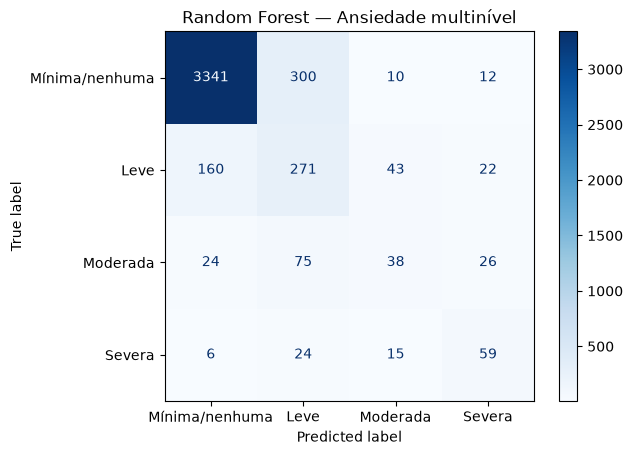

In [6]:
y_pred = modelo_final.predict(X_test)
y_proba = modelo_final.predict_proba(X_test)

print("Relatório de classificação (ponderado pelos pesos amostrais):")
print(classification_report(
    y_test, y_pred, labels=[1, 2, 3, 4],
    sample_weight=w_test,
    target_names=["Mínima/nenhuma", "Leve", "Moderada", "Severa"],
    zero_division=0
))

print("Acurácia:", round(accuracy_score(y_test, y_pred, sample_weight=w_test), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_test, y_pred, sample_weight=w_test), 4))
print("F1-macro ponderado:", round(f1_score(y_test, y_pred, labels=[1,2,3,4], average="macro", sample_weight=w_test, zero_division=0), 4))
print("ROC-AUC OvR ponderado:", round(roc_auc_score(
    y_test, y_proba, labels=[1,2,3,4], multi_class="ovr",
    average="macro", sample_weight=w_test
), 4))

cm_amostral = confusion_matrix(y_test, y_pred, labels=[1,2,3,4])
cm_ponderada = confusion_matrix(y_test, y_pred, labels=[1,2,3,4], sample_weight=w_test)
print("Matriz de confusão — contagem de registros:")
print(cm_amostral)
print("Matriz de confusão — soma dos pesos amostrais (estimativa ponderada):")
print(np.round(cm_ponderada).astype(int))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=[1,2,3,4],
    display_labels=["Mínima/nenhuma", "Leve", "Moderada", "Severa"],
    cmap="Blues", values_format="d"
)
plt.title("Random Forest — Ansiedade multinível")
plt.show()


## 7. Importância das variáveis

,feature_transformada,importancia
140,cat__FREQ_SENTIU_DEPRIMIDO_2SEM_1,0.065438
156,cat__FREQ_AUTOAVALIACAO_NEGTIVA_2SEM_1,0.041734
2,num__RAZAO_RENDA_POBREZA,0.039504
0,num__IDADE,0.037821
148,cat__FREQ_CANSASO_2SEM_1,0.032239
136,cat__FREQ_PERDA_INTERESSE_2SEM_1,0.032220
147,cat__FREQ_DIFICULDADE_DORMIR_2SEM_4,0.029190
159,cat__FREQ_AUTOAVALIACAO_NEGTIVA_2SEM_4,0.027893
151,cat__FREQ_CANSASO_2SEM_4,0.027133
160,cat__FREQ_DIFICULDADE_CONCENTRACAO_2SEM_1,0.026151


,variavel_original_aprox,importancia
22,FREQ_SENTIU_DEPRIMIDO_2SEM,0.091376
16,FREQ_AUTOAVALIACAO_NEGTIVA_2SEM,0.084933
17,FREQ_CANSASO_2SEM,0.072231
19,FREQ_DIFICULDADE_DORMIR_2SEM,0.060273
21,FREQ_PERDA_INTERESSE_2SEM,0.049562
18,FREQ_DIFICULDADE_CONCENTRACAO_2SEM,0.047562
38,RAZAO_RENDA_POBREZA,0.039504
28,IDADE,0.037821
20,FREQ_HIPOREXIA_COMPULSAO_ALIMENTAR_2SEM,0.032865
31,MODIFICACAO_VELOCIDADE_FALA,0.026802


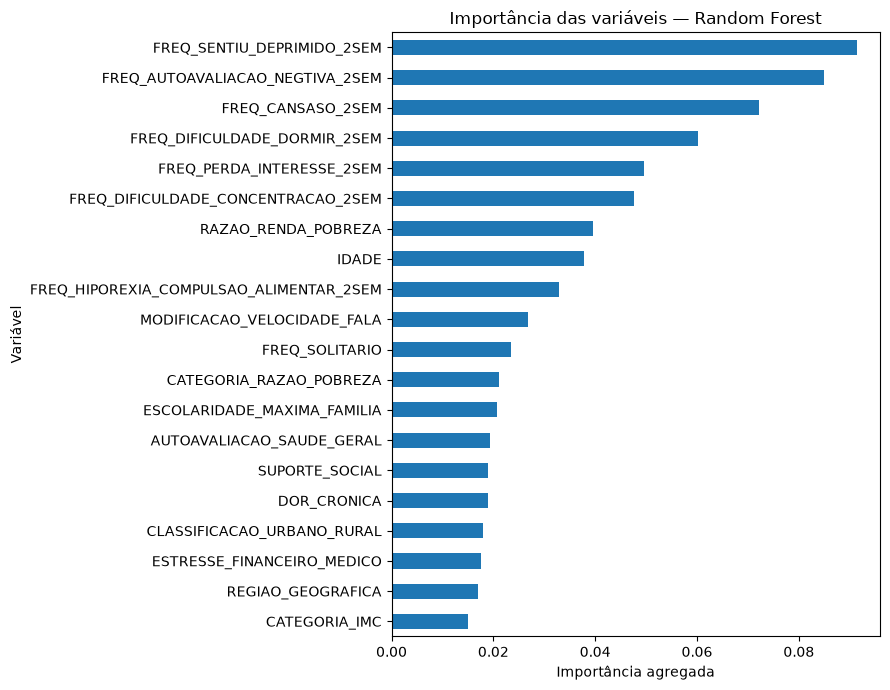

In [7]:
# Importância por variável original: soma das importâncias das categorias One-Hot
# pertencentes à mesma variável, para facilitar a interpretação.
prep = modelo_final.named_steps["preprocessor"]
rf = modelo_final.named_steps["model"]

feature_names = prep.get_feature_names_out()
importancias = pd.DataFrame({
    "feature_transformada": feature_names,
    "importancia": rf.feature_importances_
}).sort_values("importancia", ascending=False)

display(importancias.head(25))

# Importância agregada por coluna original
def nome_variavel_original(nome):
    if nome.startswith("num__"):
        return nome.replace("num__", "", 1)
    if nome.startswith("cat__"):
        resto = nome.replace("cat__", "", 1)
        # Encontra o nome original completo, inclusive quando contém underscores.
        candidatas = [c for c in cat_cols if resto.startswith(c + "_")]
        if candidatas:
            return max(candidatas, key=len)
        return resto
    return nome

importancias["variavel_original_aprox"] = importancias["feature_transformada"].map(nome_variavel_original)
importancia_agregada = (
    importancias.groupby("variavel_original_aprox", as_index=False)["importancia"]
    .sum().sort_values("importancia", ascending=False)
)
display(importancia_agregada.head(20))

importancia_agregada.head(20).sort_values("importancia").plot(
    x="variavel_original_aprox", y="importancia", kind="barh",
    figsize=(9, 7), legend=False
)
plt.xlabel("Importância agregada")
plt.ylabel("Variável")
plt.title("Importância das variáveis — Random Forest")
plt.tight_layout()
plt.show()
